# TP3 : normalisation, mots vides, racines et lemmes
**Traitement Automatique du Langage Naturel · EMSI · Chapitre 2 (partie 3) · Séance 8**

### Objectifs
1. utiliser et **adapter** une liste de mots vides (sans perdre la négation) ;
2. comparer la **racinisation** (Snowball, NLTK) et la **lemmatisation** (spaCy), en français et en anglais ;
3. **normaliser** un texte arabe (darija) ;
4. **mesurer** la taille du vocabulaire après chaque étape et **justifier** les choix.

### Mode d'emploi
- Complétez les cellules marquées `# À compléter` (remplacez les `...`).
- Exécutez ensuite la cellule **✅ Test** qui suit : elle doit afficher ✅.
- Répondez aux questions ✍️ dans la cellule « Votre réponse » placée juste en dessous.

### Livrable attendu
Le tableau comparatif commenté de la partie 4 et la fonction `normaliser_tp3()`.

## Partie 0 : préparation
### 0.1 Identification
Complétez vos informations puis exécutez la cellule : elle affiche le **nom du fichier** sous lequel
vous devez enregistrer et rendre votre notebook.

In [1]:
NOM = "EZZIRANI"
PRENOM = "Anwar"
GROUPE = 'G4'

assert NOM and PRENOM and GROUPE, "Complétez NOM, PRENOM et GROUPE"
nom_fichier = f"TP3_{NOM}_{PRENOM}_{GROUPE}.ipynb".replace(" ", "_")
print("Enregistrez votre notebook sous le nom :", nom_fichier)

Enregistrez votre notebook sous le nom : TP3_EZZIRANI_Anwar_G4.ipynb


### 0.2 Installation et imports
Sur **Google Colab**, décommentez les 3 premières lignes la première fois (NLTK est déjà installé).
Sur votre machine : `pip install nltk spacy pandas matplotlib`, puis téléchargez les deux modèles spaCy.

In [2]:
# !pip install -q spacy
# !python -m spacy download fr_core_news_sm
# !python -m spacy download en_core_web_sm

import re, html, unicodedata
from collections import Counter

import nltk
try:
    nltk.data.find("corpora/stopwords")
except LookupError:
    nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
from nltk.stem import PorterStemmer
from nltk.stem.isri import ISRIStemmer

import spacy
import pandas as pd
import matplotlib.pyplot as plt

nlp_fr = spacy.load("fr_core_news_sm")    # modèle français
nlp_en = spacy.load("en_core_web_sm")     # modèle anglais
print("NLTK", nltk.__version__, "| spaCy", spacy.__version__, "| pandas", pd.__version__)

NLTK 3.9.4 | spaCy 3.8.16 | pandas 2.2.1


### 0.3 Le corpus fil rouge
Trois petits corpus d'avis sur des restaurants, chacun avec son étiquette (`"pos"` ou `"neg"`) :
- `AVIS` : 26 avis **en français** ;
- `DARIJA` : 8 avis en **darija** écrits en lettres arabes, et 2 en **arabizi** ;
- `ENGLISH` : 6 avis **en anglais**.

In [3]:
AVIS = [
    ("Le tajine était délicieux et le service très rapide. Je recommande !", "pos"),
    ("Service TRÈS lent, le plat est arrivé froid. Je ne recommande pas.", "neg"),
    ("Les serveurs sont aimables et le cadre est magnifique 😍", "pos"),
    ("Le couscous n'était pas bon du tout, trop salé.", "neg"),
    ("Trooop bien !!! Livraison rapide et repas encore chaud.", "pos"),
    ("Livraison en retard de 45 minutes, la commande était incomplète.", "neg"),
    ("Très bon rapport qualité-prix, les portions sont généreuses.", "pos"),
    ("Le restaurant est sale et le personnel n'est pas aimable.", "neg"),
    ("J'ai adoré le thé à la menthe et les pâtisseries marocaines.", "pos"),
    ("Les prix sont trop élevés pour des plats sans goût.", "neg"),
    ("Accueil chaleureux, on s'est régalés en famille. Merci @dar_tajine !", "pos"),
    ("Plus jamais ! Le poisson n'était pas frais.", "neg"),
    ("Cadre agréable, musique douce, serveurs souriants.", "pos"),
    ("Commande annulée sans explication, service client injoignable.", "neg"),
    ("Le meilleur restaurant de Rabat, les brochettes sont excellentes.", "pos"),
    ("Les frites étaient froides et la sauce n'avait aucun goût.", "neg"),
    ("tres bon resto, je reviendrai avec mes amis", "pos"),
    ("Pas bon, pas chaud, pas rapide : rien ne va.", "neg"),
    ("Réservation facile sur https://dar-tajine.ma et accueil parfait.", "pos"),
    ("Le service était lent mais les plats étaient bons.", "pos"),
    ("Je ne suis pas satisfait, le livreur était impoli.", "neg"),
    ("Une expérience inoubliable, tout était parfait !", "pos"),
    ("Le restaurent est magnifque, les serveurs très gentils.", "pos"),
    ("Les plats sont arrivés froids, je ne commanderai plus jamais.", "neg"),
    ("Le plat est bon.", "pos"),
    ("Le plat n'est pas bon.", "neg"),
]

DARIJA = [
    ("الطاجين كان بنين بزاف و السيرفيس مزيان", "pos"),
    ("الماكلة باردة و الثمن غالي، ما عجبنيش", "neg"),
    ("المطعـــم زوين و الخدمة سريعة 👍", "pos"),
    ("ما غاديش نرجع ليه، الخدمة خايبة", "neg"),
    ("أحسن مطعم فالرباط، شُكْرًا بزااااف", "pos"),
    ("احسن طاجين كليتو، الأثمنة مناسبة", "pos"),
    ("التوصيل تعطل ساعة و الماكلة ما كانتش سخونة", "neg"),
    ("إلى بغيتي تاكل مزيان سير لهاد المطعم", "pos"),
    ("lmakla bnina bzaf, 3jbatni", "pos"),           # arabizi
    ("service 5ayb, ma 3jbnich", "neg"),             # arabizi
]

ENGLISH = [
    ("The waiters were friendly and the dishes tasted amazing.", "pos"),
    ("We waited two hours and the fries were cold.", "neg"),
    ("Best restaurant in Rabat, the tagines are delicious!", "pos"),
    ("The rooms were dirty and the staff wasn't helpful.", "neg"),
    ("The delivery arrived late and the boxes were broken.", "neg"),
    ("Lovely views, generously served meals and cheaper prices.", "pos"),
]
print(len(AVIS), "avis FR |", len(DARIJA), "avis darija |", len(ENGLISH), "avis EN")
print(Counter(etiquette for _, etiquette in AVIS))

26 avis FR | 10 avis darija | 6 avis EN
Counter({'pos': 14, 'neg': 12})


### 0.4 Le prétraitement du TP2 et l'analyse spaCy
La fonction `preprocess()` ci-dessous est une **version simplifiée** de celle du TP2 (vous pouvez la remplacer
par la vôtre). Elle remplace les liens par `<URL>`, les mentions par `<USER>` et réduit les allongements.

Pour que spaCy garde `<URL>` et `<USER>` en **un seul token**, on lui déclare deux **cas particuliers**.

In [4]:
def preprocess(texte):
    """Prétraitement du TP2 (version simplifiée)."""
    texte = html.unescape(texte)                       # &amp; -> &
    texte = re.sub(r"https?://\S+", " <URL> ", texte)  # liens
    texte = re.sub(r"@\w+", " <USER> ", texte)         # mentions
    texte = re.sub(r"(\w)\1{2,}", r"\1\1", texte)      # trooop -> troop
    return re.sub(r"\s+", " ", texte).strip()

for jeton in ["<URL>", "<USER>"]:                      # 1 token, pas 3
    nlp_fr.tokenizer.add_special_case(jeton, [{"ORTH": jeton}])

textes = [preprocess(t) for t, _ in AVIS]
docs = list(nlp_fr.pipe(textes))                       # analyse de tout le corpus
print(textes[18])
print([t.text for t in docs[18]])

Réservation facile sur <URL> et accueil parfait.
['Réservation', 'facile', 'sur', '<URL>', 'et', 'accueil', 'parfait', '.']


## Partie 1 : les mots vides
### Exercice 1.1 : comparer les listes de NLTK et de spaCy
Les deux bibliothèques fournissent une liste de mots vides français. Comparez-les avec les **opérations
sur les ensembles** : `&` (intersection), `-` (différence).

👉 La liste de spaCy se trouve dans `nlp_fr.Defaults.stop_words`.

In [5]:
sw_nltk = set(stopwords.words("french"))
sw_spacy = set(nlp_fr.Defaults.stop_words)

communs = sw_nltk & sw_spacy
seulement_nltk = sw_nltk - sw_spacy
seulement_spacy = sw_spacy - sw_nltk

print("NLTK :", len(sw_nltk), "| spaCy :", len(sw_spacy), "| communs :", len(communs))
print("Seulement NLTK (15 premiers) :", sorted(seulement_nltk)[:15])
print("Seulement spaCy (15 premiers) :", sorted(seulement_spacy)[:15])

NLTK : 157 | spaCy : 507 | communs : 85
Seulement NLTK (15 premiers) : ['aient', 'aies', 'aurai', 'aurais', 'auras', 'aurez', 'auriez', 'aurions', 'aurons', 'avez', 'aviez', 'avions', 'ayante', 'ayantes', 'ayants']
Seulement spaCy (15 premiers) : ['a', 'abord', 'afin', 'ah', 'ainsi', 'allaient', 'allons', 'alors', 'anterieur', 'anterieure', 'anterieures', 'antérieur', 'antérieure', 'antérieures', 'apres']


In [6]:
# ✅ Test 1.1 (ne pas modifier)
assert isinstance(sw_spacy, set) and "le" in sw_spacy, "sw_spacy doit être un set (utilisez set(...))"
assert communs == sw_nltk & sw_spacy, "communs : mots présents dans les deux listes (opérateur &)"
assert seulement_nltk == sw_nltk - sw_spacy, "seulement_nltk : opérateur -"
assert seulement_spacy == sw_spacy - sw_nltk, "seulement_spacy : opérateur -"
print("✅ Exercice 1.1 réussi")

✅ Exercice 1.1 réussi


Observez : NLTK contient `"l"`, `"n"`, `"qu"` **sans apostrophe**, alors que spaCy découpe `l'`, `n'`, `qu'`
**avec** l'apostrophe. Vérifions quels mots de la négation sont dans chaque liste :

In [7]:
for mot in ["ne", "n'", "n", "pas", "plus", "jamais", "rien", "aucun", "sans", "très", "trop", "mais"]:
    print(f"{mot:7} NLTK : {str(mot in sw_nltk):5}  spaCy : {mot in sw_spacy}")

ne      NLTK : True   spaCy : True
n'      NLTK : False  spaCy : True
n       NLTK : True   spaCy : False
pas     NLTK : True   spaCy : True
plus    NLTK : False  spaCy : True
jamais  NLTK : False  spaCy : False
rien    NLTK : False  spaCy : False
aucun   NLTK : False  spaCy : False
sans    NLTK : False  spaCy : True
très    NLTK : False  spaCy : True
trop    NLTK : False  spaCy : False
mais    NLTK : True   spaCy : True


✍️ **Réponse 1.1.** spaCy contient 507 mots vides, contre 157 pour NLTK (85 sont communs).
NLTK contient `n` mais pas `n'` : son inventaire ne correspond pas au découpage de spaCy, qui produit `n'`.
Parmi les formes de négation proposées, `ne` et `pas` figurent dans les deux listes ; `n'` et `plus` ne sont que dans spaCy.

### Exercice 1.2 : quelle part du corpus représentent les mots vides ?
1. Construisez la liste `mots` de tous les tokens **alphabétiques** du corpus, en minuscules
   (attributs spaCy `t.is_alpha` et `t.lower_`).
2. Comptez-les avec `Counter` et affichez les 10 plus fréquents.
3. Calculez la **proportion** de tokens qui sont des mots vides (liste spaCy).

In [8]:
mots = [t.lower_ for doc in docs for t in doc if t.is_alpha]
freq = Counter(mots)
top10 = freq.most_common(10)

nb_vides = sum(m in sw_spacy for m in mots)
proportion = nb_vides / len(mots)

print(len(mots), "tokens,", len(freq), "mots différents")
print(top10)
print(f"Mots vides : {nb_vides} tokens, soit {proportion:.0%} du corpus")

219 tokens, 119 mots différents
[('le', 15), ('pas', 9), ('les', 9), ('est', 8), ('était', 7), ('et', 7), ('bon', 6), ('je', 5), ('sont', 5), ('service', 4)]
Mots vides : 105 tokens, soit 48% du corpus


In [9]:
# ✅ Test 1.2
assert isinstance(mots, list) and all(m == m.lower() and m.isalpha() for m in mots), "mots : tokens alphabétiques en minuscules"
assert freq == Counter(mots), "freq doit être Counter(mots)"
assert len(top10) == 10 and top10[0] == freq.most_common(1)[0], "top10 : freq.most_common(10)"
assert abs(proportion - sum(m in sw_spacy for m in mots) / len(mots)) < 1e-9, "proportion incorrecte"
print("✅ Exercice 1.2 réussi")

✅ Exercice 1.2 réussi


### Exercice 1.3 : retirer les mots vides… et perdre la négation
Écrivez la fonction `retirer_mots_vides(tokens, mots_vides)` qui renvoie la liste des tokens qui ne sont
**ni** des mots vides **ni** de la ponctuation. `tokens` est une liste de tokens spaCy ; on renvoie leur
forme en minuscules (`t.lower_`).

In [10]:
def retirer_mots_vides(tokens, mots_vides):
    """Retire la ponctuation et les mots vides, sans modifier les autres tokens."""
    return [t.lower_ for t in tokens if not t.is_punct and t.lower_ not in mots_vides]

for phrase in ["Le plat est bon.", "Le plat n'est pas bon.", "Le plat n'est jamais bon."]:
    doc = nlp_fr(phrase)
    print(f"{phrase:28}", retirer_mots_vides(doc, sw_spacy))

Le plat est bon.             ['plat', 'bon']
Le plat n'est pas bon.       ['plat', 'bon']
Le plat n'est jamais bon.    ['plat', 'jamais', 'bon']


In [11]:
# ✅ Test 1.3
assert retirer_mots_vides(nlp_fr("Le service est rapide !"), sw_spacy) == ["service", "rapide"], "retirez les mots vides ET la ponctuation, en minuscules"
assert retirer_mots_vides(nlp_fr("Le plat n'est pas bon."), set()) == ["le", "plat", "n'", "est", "pas", "bon"], "avec une liste vide, seule la ponctuation doit partir"
print("✅ Exercice 1.3 réussi")

✅ Exercice 1.3 réussi


✍️ **Réponse 1.3.** Avec la liste spaCy brute, « Le plat est bon » et « Le plat n'est pas bon » deviennent tous deux `['plat', 'bon']`.
Un classifieur de sentiment perd alors le signal qui inverse la polarité de la seconde phrase.
« jamais » reste car il n'appartient pas à la liste française de mots vides de spaCy utilisée ici.

### Exercice 1.4 : construire une liste adaptée au corpus
On part de la liste de spaCy et :
1. on **retire** de la liste les mots de la négation (`NEGATION`) et d'intensité (`INTENSITE`), qu'on veut **garder** ;
2. on **ajoute** des mots du domaine, très fréquents dans tous les avis et donc peu utiles pour les distinguer.

Pour choisir les mots du domaine, la cellule suivante calcule la **fréquence documentaire** : le nombre
d'avis dans lesquels chaque mot (non vide) apparaît.

In [12]:
df = Counter()
for doc in docs:
    df.update({t.lower_ for t in doc if t.is_alpha and t.lower_ not in sw_spacy})
print(df.most_common(10))

[('bon', 6), ('service', 4), ('rapide', 3), ('plat', 3), ('serveurs', 3), ('plats', 3), ('recommande', 2), ('lent', 2), ('cadre', 2), ('trop', 2)]


In [13]:
NEGATION = {"ne", "n'", "pas", "plus", "jamais", "rien", "aucun", "aucune", "sans", "ni"}
INTENSITE = {"très", "trop", "peu"}
MOTS_DOMAINE = {"plat", "restaurant"}

mots_vides_tp = (sw_spacy - NEGATION - INTENSITE) | MOTS_DOMAINE

print(len(mots_vides_tp), "mots vides dans la liste adaptée")
for phrase in ["Le plat est bon.", "Le plat n'est pas bon.", "Le restaurant est très sale."]:
    print(f"{phrase:30}", retirer_mots_vides(nlp_fr(phrase), mots_vides_tp))

501 mots vides dans la liste adaptée
Le plat est bon.               ['bon']
Le plat n'est pas bon.         ["n'", 'pas', 'bon']
Le restaurant est très sale.   ['très', 'sale']


In [14]:
# ✅ Test 1.4
assert isinstance(mots_vides_tp, set), "mots_vides_tp doit être un set"
assert "le" in mots_vides_tp and "est" in mots_vides_tp, "les mots vides habituels doivent rester"
assert not ({"pas", "ne", "n'", "jamais", "très"} & mots_vides_tp), "la négation et l'intensité doivent être GARDÉES"
assert MOTS_DOMAINE and MOTS_DOMAINE <= mots_vides_tp, "ajoutez vos mots du domaine"
assert retirer_mots_vides(nlp_fr("Le plat est bon."), mots_vides_tp) != retirer_mots_vides(nlp_fr("Le plat n'est pas bon."), mots_vides_tp)
print("✅ Exercice 1.4 réussi : la négation est conservée")

✅ Exercice 1.4 réussi : la négation est conservée


✍️ **Réponse 1.4.** J'ajoute `plat` (présent dans 3 avis) et `restaurant` (2 avis), deux termes qui décrivent le domaine plutôt que la polarité.
Le choix se fonde sur la fréquence documentaire `df` : ces mots reviennent dans plusieurs avis, positifs et négatifs ; `plats` reste distinct de `plat` à ce stade.
`service` (4 avis) peut porter une information d'aspect (« service lent/rapide ») et `bon` (6 avis) porte directement la polarité ; je les conserve.
La faible taille du corpus rend ce choix de mots du domaine expérimental.

### 2.1 À la main d'abord
Prédictions faites avant l'exécution, puis comparées à Snowball :

| Mot | Prédiction | Snowball |
|---|---|---|
| mangeons | mang | mangeon |
| rapidement | rapid | rapid |
| livraison | livr | livraison |
| livreur | livr | livreur |
| serveuse | serveus | serveux |

Les écarts montrent qu'un raciniseur ne réduit pas systématiquement tous les membres d'une famille à la même forme.

### Exercice 2.1 : la racinisation avec Snowball
Complétez la fonction `raciner(mots)` qui renvoie la liste des racines, puis la fonction `nb_racines(mots)` qui
renvoie le **nombre de racines différentes** d'une famille de mots.

In [15]:
stemmer_fr = SnowballStemmer("french")

def raciner(mots):
    return [stemmer_fr.stem(m) for m in mots]

def nb_racines(mots):
    return len(set(raciner(mots)))

familles = {
    "manger":  ["mange", "mangeons", "mangeait", "mangé", "mangeur"],
    "rapide":  ["rapide", "rapides", "rapidement", "rapidité"],
    "livrer":  ["livrer", "livraison", "livreur", "livré"],
    "servir":  ["servir", "service", "serveur", "serveuse", "servi"],
    "aller":   ["aller", "allons", "va", "irai"],
}
for nom, mots_famille in familles.items():
    print(f"{nom:8} {nb_racines(mots_famille)} racine(s) :", raciner(mots_famille))

manger   3 racine(s) : ['mang', 'mangeon', 'mang', 'mang', 'mangeur']
rapide   1 racine(s) : ['rapid', 'rapid', 'rapid', 'rapid']
livrer   3 racine(s) : ['livr', 'livraison', 'livreur', 'livr']
servir   4 racine(s) : ['serv', 'servic', 'serveur', 'serveux', 'serv']
aller    4 racine(s) : ['aller', 'allon', 'va', 'irai']


In [16]:
# ✅ Test 2.1
assert raciner(["mangeait", "rapides"]) == ["mang", "rapid"], "raciner doit renvoyer la LISTE des racines"
assert nb_racines(["mange", "mangé", "mangeait"]) == 1 and nb_racines(["va", "irai"]) == 2, "nb_racines : len(set(...))"
print("✅ Exercice 2.1 réussi")

✅ Exercice 2.1 réussi


### Exercice 2.2 : la lemmatisation avec spaCy
Écrivez `lemmatiser(texte)` qui renvoie la liste des **lemmes en minuscules** des tokens d'un texte, sans la
ponctuation. Un lemme s'obtient avec `t.lemma_`.

In [17]:
def lemmatiser(texte):
    doc = nlp_fr(texte)
    return [t.lemma_.lower() for t in doc if not t.is_punct]

print(lemmatiser("Les serveurs étaient aimables et nous avons mangé des tajines délicieux."))
print(lemmatiser("Nous irons, tu vas, ils allaient."))

['le', 'serveur', 'être', 'aimable', 'et', 'nous', 'avoir', 'manger', 'un', 'tajine', 'délicieux']
['nous', 'aller', 'tu', 'va', 'il', 'aller']


In [18]:
# ✅ Test 2.2
assert lemmatiser("Les serveurs étaient aimables.") == ["le", "serveur", "être", "aimable"], "lemmes en minuscules, sans la ponctuation"
print("✅ Exercice 2.2 réussi")

✅ Exercice 2.2 réussi


### Exercice 2.3 : tableau comparatif mot / racine / lemme
Pour chaque token (hors ponctuation) de l'avis ci-dessous, ajoutez une ligne
`{"mot": ..., "racine": ..., "lemme": ..., "catégorie": ...}` à la liste `lignes`, puis affichez le tableau
avec pandas. La catégorie s'obtient avec `t.pos_`.

In [19]:
avis = "Les serveurs étaient souriants mais les livraisons arrivaient froides."
lignes = []
for t in nlp_fr(avis):
    if not t.is_punct:
        lignes.append({"mot": t.lower_, "racine": stemmer_fr.stem(t.lower_),
                       "lemme": t.lemma_.lower(), "catégorie": t.pos_})

tableau = pd.DataFrame(lignes)
tableau

,mot,racine,lemme,catégorie
0,les,le,le,DET
1,serveurs,serveur,serveur,NOUN
2,étaient,étaient,être,AUX
3,souriants,souri,souriant,ADJ
4,mais,mais,mais,CCONJ
5,les,le,le,DET
6,livraisons,livraison,livraison,NOUN
7,arrivaient,arriv,arriver,VERB
8,froides,froid,froid,ADJ


In [20]:
# ✅ Test 2.3
assert list(tableau.columns) == ["mot", "racine", "lemme", "catégorie"], "4 colonnes : mot, racine, lemme, catégorie"
assert len(tableau) == 9 and tableau.loc[0, "lemme"] == "le", "une ligne par token (9 tokens hors ponctuation)"
print("✅ Exercice 2.3 réussi")

✅ Exercice 2.3 réussi


✍️ **Réponse 2.3.** `souriants` donne une racine tronquée (`souri`) qui n'est pas un mot français autonome, alors que le lemme `souriant` reste lisible.
Le lemme `être` pour `étaient` est aussi plus utile que sa racine : il regroupe les formes fléchies d'un verbe sous sa forme de dictionnaire.
La racinisation est simple, rapide et ne dépend pas d'un modèle grammatical ; elle peut cependant confondre ou séparer à tort des formes.

### Exercice 2.4 : et en anglais ?
Comparez **Porter**, **Snowball (english)** et les lemmes de **spaCy (anglais)** sur les tokens alphabétiques des
avis `ENGLISH`. Construisez un tableau avec une ligne par mot **différent**.

In [21]:
porter = PorterStemmer()
snow_en = SnowballStemmer("english")

lignes_en = []
deja_vus = set()
for texte, _ in ENGLISH:
    for t in nlp_en(texte):
        mot = t.lower_
        if t.is_alpha and mot not in deja_vus:
            deja_vus.add(mot)
            lignes_en.append({"mot": mot, "Porter": porter.stem(mot),
                              "Snowball": snow_en.stem(mot),
                              "lemme spaCy": t.lemma_.lower()})

tableau_en = pd.DataFrame(lignes_en)
tableau_en[(tableau_en["Porter"] != tableau_en["mot"]) |
           (tableau_en["lemme spaCy"] != tableau_en["mot"])]

,mot,Porter,Snowball,lemme spaCy
1,waiters,waiter,waiter,waiter
2,were,were,were,be
3,friendly,friendli,friend,friendly
5,dishes,dish,dish,dish
6,tasted,tast,tast,taste
7,amazing,amaz,amaz,amazing
9,waited,wait,wait,wait
11,hours,hour,hour,hour
12,fries,fri,fri,fry
14,best,best,best,good


In [22]:
# ✅ Test 2.4
assert list(tableau_en.columns) == ["mot", "Porter", "Snowball", "lemme spaCy"]
ligne = tableau_en[tableau_en["mot"] == "were"].iloc[0]
assert ligne["lemme spaCy"] == "be" and ligne["Porter"] == "were"
print("✅ Exercice 2.4 réussi")

✅ Exercice 2.4 réussi


✍️ **Réponse 2.4.** `were` est ramené à `be` par le modèle spaCy, alors que Porter garde `were`.
Porter transforme `generously` en `gener`, forme peu lisible.
Pour `friendly`, Porter produit `friendli` et Snowball `friend` : les deux règles de suffixe ne donnent pas la même racine.

### Exercice 2.5 : repérer la sur-racinisation dans le corpus
Une racine peut regrouper des mots de **sens différents**. Pour le vérifier, on associe à chaque racine
l'ensemble des **lemmes** qui la produisent. Une racine avec plusieurs lemmes est **suspecte**.

In [23]:
racine_vers_lemmes = {}
for doc in docs:
    for t in doc:
        if t.is_alpha and t.lower_ not in mots_vides_tp:
            r = stemmer_fr.stem(t.lower_)
            racine_vers_lemmes.setdefault(r, set()).add(t.lemma_.lower())

suspects = {r: lemmes for r, lemmes in racine_vers_lemmes.items() if len(lemmes) >= 2}
for r, lemmes in sorted(suspects.items()):
    print(f"{r:10} <- {sorted(lemmes)}")

command    <- ['commande', 'commander']
froid      <- ['froid', 'froider']
sal        <- ['sale', 'salé']


In [24]:
# ✅ Test 2.5
assert all(len(l) >= 2 for l in suspects.values()) and len(suspects) >= 1
print("✅ Exercice 2.5 réussi :", len(suspects), "racine(s) suspecte(s)")

✅ Exercice 2.5 réussi : 3 racine(s) suspecte(s)


✍️ **Réponse 2.5.** `sal` regroupe `sale` et `salé`, deux adjectifs de sens distinct : c'est une vraie sur-racinisation, dangereuse pour le sentiment.
`command` regroupe `commande` (nom) et `commander` (verbe) : les lemmes diffèrent, mais ils appartiennent à la même famille sémantique ; ce n'est pas une collision de sens manifeste.
`froid` associe `froid` à `froider` : le modèle spaCy a interprété `froides` comme un verbe ; c'est une erreur de lemmatisation dans ce contexte.
Une racine associée à plusieurs lemmes n'est donc qu'un signal à examiner manuellement, pas une preuve de sur-racinisation.

## Partie 3 : normaliser l'arabe (darija)
### Exercice 3.1 : compléter `normaliser_arabe()`
Les étapes 1 et 2 sont données. Complétez les étapes 3 à 6 (voir le cours, partie 3) :

| Étape | Opération | Exemple |
|---|---|---|
| 3 | formes de alef أ إ آ → ا | أحمد devient احمد |
| 4 | alef maqsura ى → ي | إلى devient الي |
| 5 | ta marbuta ة → ه | مدرسة devient مدرسه |
| 6 | chiffres arabes-indiens ٠…٩ → 0…9 | ٢٠٢٤ devient 2024 |

Les lettres sont écrites avec leur **code Unicode** (`"\u0623"` = أ) pour que le code reste lisible.

In [25]:
def normaliser_arabe(t):
    t = re.sub("[\u064B-\u0652]", "", t)  # 1. voyelles brèves
    t = t.replace("\u0640", "")           # 2. tatweel
    t = t.translate(str.maketrans({"\u0623": "\u0627", "\u0625": "\u0627", "\u0622": "\u0627"}))
    t = t.replace("\u0649", "\u064A")   # 4. alef maqsura -> ya
    t = t.replace("\u0629", "\u0647")   # 5. ta marbuta -> ha
    t = t.translate(str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789"))  # 6. chiffres
    return t

for mot in ["أحمد", "إلى", "مدرسة", "شُكْرًا", "المطعـــم", "٢٠٢٤"]:
    print("avant :", mot, "| après :", normaliser_arabe(mot))

avant : أحمد | après : احمد
avant : إلى | après : الي
avant : مدرسة | après : مدرسه
avant : شُكْرًا | après : شكرا
avant : المطعـــم | après : المطعم
avant : ٢٠٢٤ | après : 2024


In [26]:
# ✅ Test 3.1
tests = {"أحمد": "احمد", "إلى": "الي", "مدرسة": "مدرسه", "شُكْرًا": "شكرا", "المطعـــم": "المطعم", "٢٠٢٤": "2024"}
for avant, attendu in tests.items():
    assert normaliser_arabe(avant) == attendu, f"{avant} devrait donner {attendu}, pas {normaliser_arabe(avant)}"
print("✅ Exercice 3.1 réussi")

✅ Exercice 3.1 réussi


## Partie 4 : mesurer la taille du vocabulaire (livrable)
On applique les étapes **une par une** au corpus français et on mesure, après chaque étape :
- le **nombre de tokens** (la longueur totale des textes) ;
- la **taille du vocabulaire** (le nombre de mots **différents**).

La fonction `sans_accents()` du cours est fournie.

In [27]:
def sans_accents(mot):
    nfd = unicodedata.normalize("NFD", mot)
    return "".join(c for c in nfd if unicodedata.category(c) != "Mn")

print(sans_accents("Très élevés, ça coûte cher"))

Tres eleves, ca coute cher


### Exercice 4.1 : deux fonctions de mesure
`listes` est une liste de listes de tokens (une liste par avis).

In [28]:
def nb_tokens(listes):
    return sum(len(liste) for liste in listes)

def taille_vocabulaire(listes):
    return len({mot for liste in listes for mot in liste})

exemple = [["le", "plat", "est", "bon"], ["le", "plat", "est", "froid"]]
print(nb_tokens(exemple), taille_vocabulaire(exemple))

8 5


In [29]:
# ✅ Test 4.1
assert nb_tokens(exemple) == 8 and taille_vocabulaire(exemple) == 5, "attendu : 8 tokens et 5 mots différents"
assert nb_tokens([]) == 0 and taille_vocabulaire([[]]) == 0, "cas des listes vides"
print("✅ Exercice 4.1 réussi")

✅ Exercice 4.1 réussi


### Exercice 4.2 : le tableau comparatif
Complétez le dictionnaire `etapes` : chaque étape associe à chaque avis la liste de ses tokens transformés.
Les étapes sont **cumulatives** (chacune reprend la précédente). La fonction `garde(t)` (fournie) indique si un
token est conservé après le retrait de la ponctuation et des mots vides de **votre** liste adaptée.

In [30]:
def garde(t):
    return not t.is_punct and not t.is_space and t.lower_ not in mots_vides_tp

etapes = {
    "0. tokens bruts":        [[t.text for t in d] for d in docs],
    "1. minuscules":          [[t.lower_ for t in d] for d in docs],
    "2. sans ponctuation":    [[t.lower_ for t in d if not t.is_punct and not t.is_space] for d in docs],
    "3. sans accents":        [[sans_accents(t.lower_) for t in d if not t.is_punct and not t.is_space] for d in docs],
    "4. sans mots vides":     [[sans_accents(t.lower_) for t in d if garde(t)] for d in docs],
    "5a. racines (Snowball)": [[stemmer_fr.stem(sans_accents(t.lower_)) for t in d if garde(t)] for d in docs],
    "5b. lemmes (spaCy)":     [[sans_accents(t.lemma_.lower()) for t in d if garde(t)] for d in docs],
}

v0 = taille_vocabulaire(etapes["0. tokens bruts"])
resultats = pd.DataFrame([
    {"étape": nom, "tokens": nb_tokens(l), "vocabulaire": taille_vocabulaire(l),
     "réduction du vocabulaire": f"{1 - taille_vocabulaire(l) / v0:.0%}"}
    for nom, l in etapes.items()])
resultats

,étape,tokens,vocabulaire,réduction du vocabulaire
0,0. tokens bruts,279,142,0%
1,1. minuscules,279,131,8%
2,2. sans ponctuation,230,126,11%
3,3. sans accents,230,124,13%
4,4. sans mots vides,139,92,35%
5,5a. racines (Snowball),139,86,39%
6,5b. lemmes (spaCy),139,87,39%


In [31]:
# ✅ Test 4.2
assert all(isinstance(v, list) and len(v) == len(docs) for v in etapes.values()), "une liste par avis pour chaque étape"
voc = list(resultats["vocabulaire"])
assert voc[0] >= voc[1] >= voc[2] >= voc[3] >= voc[4], "les étapes 0 à 4 doivent réduire le vocabulaire"
assert "pas" in {m for l in etapes["5b. lemmes (spaCy)"] for m in l}, "la négation doit être conservée"
print("✅ Exercice 4.2 réussi")

✅ Exercice 4.2 réussi


### Exercice 4.3 : visualiser
Tracez un diagramme en barres horizontales de la taille du vocabulaire à chaque étape (`plt.barh`).

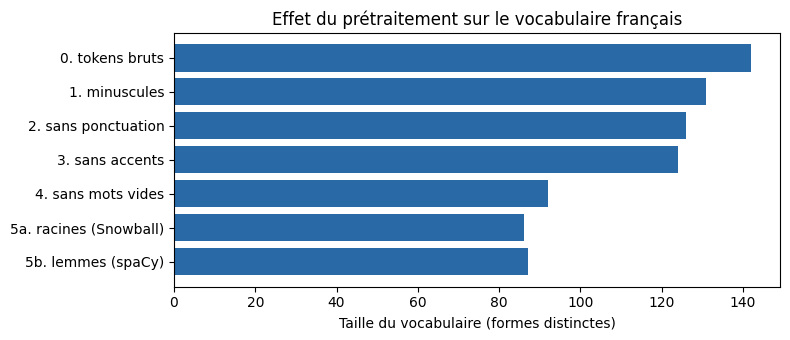

In [32]:
plt.figure(figsize=(8, 3.5))
plt.barh(resultats["étape"], resultats["vocabulaire"], color="#2869a6")
plt.gca().invert_yaxis()
plt.xlabel("Taille du vocabulaire (formes distinctes)")
plt.title("Effet du prétraitement sur le vocabulaire français")
plt.tight_layout()
plt.show()

### Exercice 4.4 : la fonction finale `normaliser_tp3()`
Assemblez **votre** chaîne de traitement dans une fonction réutilisable (TP6, TP8) :
`preprocess` → spaCy → retrait de la ponctuation et des mots vides adaptés → **lemmes** (par défaut) ou **racines**.

In [33]:
def normaliser_tp3(texte, methode="lemmes"):
    doc = nlp_fr(preprocess(texte))
    if methode == "lemmes":
        return [t.lemma_.lower() for t in doc if garde(t)]
    elif methode == "racines":
        return [stemmer_fr.stem(t.lower_) for t in doc if garde(t)]
    raise ValueError("methode doit être 'lemmes' ou 'racines'")

for texte, etiquette in AVIS[:3] + AVIS[-2:]:
    print(etiquette, normaliser_tp3(texte))

pos ['tajine', 'délicieux', 'service', 'très', 'rapide', 'recommander']


neg ['service', 'très', 'lent', 'arriver', 'froid', 'ne', 'recommander', 'pas']
pos ['serveur', 'aimable', 'cadre', 'magnifique', '😍']
pos ['bon']
neg ['ne', 'pas', 'bon']


In [34]:
# ✅ Test 4.4
assert normaliser_tp3("Les serveurs étaient aimables !") == ["serveur", "aimable"], "méthode lemmes : garde(t) et t.lemma_.lower()"
assert normaliser_tp3("Les serveurs étaient aimables !", "racines") == ["serveur", "aimabl"], "méthode racines : stemmer_fr.stem(t.lower_)"
assert normaliser_tp3("Le plat est bon.") != normaliser_tp3("Le plat n'est pas bon."), "la négation doit être conservée"
print("✅ Exercice 4.4 réussi : normaliser_tp3() est prête pour les TP suivants")

✅ Exercice 4.4 réussi : normaliser_tp3() est prête pour les TP suivants


### ✍️ Conclusion (livrable)

1. Sur 26 avis français, on passe de 279 tokens et 142 formes distinctes à 139 tokens et 87 lemmes distincts.
2. Le retrait des mots vides adaptés réduit le plus le vocabulaire d'une étape à la suivante : 124 → 92 formes (−32).
3. Le plus gros retrait de tokens vient aussi de cette étape : 230 → 139 (−91) ; la ponctuation en enlève 49.
4. Snowball donne 86 racines distinctes contre 87 lemmes : les racines réduisent ici légèrement plus le vocabulaire.
5. Cette différence vient des suffixes coupés sans analyse grammaticale ; `sale` et `salé` fusionnent sous `sal`.
6. Les minuscules effacent la casse (`TRÈS`), et la suppression des accents rapproche des graphies comme `très` et `tres`.
7. La ponctuation et les mots vides effacent des indices de forme et de syntaxe ; les mots du domaine `plat` et `restaurant` disparaissent.
8. Pour le sentiment, je choisis `preprocess` → spaCy → mots vides adaptés → lemmes, en gardant `n'`, `pas`, `très` et `trop`.
9. Ainsi « Le plat est bon » donne `['bon']`, tandis que « Le plat n'est pas bon » donne `["n'", 'pas', 'bon']`.

## Pour aller plus loin (étudiants rapides)
### A. Un correcteur orthographique sur le corpus
Le corpus contient des fautes de frappe (« restaurent », « magnifque »). Utilisez la distance de Levenshtein du
cours pour proposer une correction : un mot **rare** (vu une seule fois) est remplacé par le mot **fréquent**
le plus proche, s'il est à une distance de 1 ou 2.

In [35]:
from nltk.metrics.distance import edit_distance     # distance de Levenshtein (cours, partie 3)

freq_mots = Counter(m for d in docs for m in (t.lower_ for t in d if t.is_alpha))
connus = {m: f for m, f in freq_mots.items() if f >= 2}  # mots vus au moins 2 fois
print(len(connus), "mots connus, ex. :", sorted(connus)[:8])

36 mots connus, ex. : ['accueil', 'bon', 'cadre', 'chaud', 'commande', 'de', 'en', 'est']


In [36]:
def corriger(mot, max_dist=2):
    mot = mot.lower()
    if mot in connus:
        return mot
    candidats = [(edit_distance(mot, connu), -frequence, connu)
                 for connu, frequence in connus.items()]
    if not candidats:
        return mot
    distance, _, meilleur = min(candidats)
    return meilleur if distance <= max_dist else mot

for m in ["restaurent", "magnifque", "servise", "tajine", "excellentes"]:
    print(f"{m:12} -> {corriger(m)}")

restaurent   -> restaurant
magnifque    -> magnifque
servise      -> service
tajine       -> tajine
excellentes  -> excellentes


✍️ **Réponse A.** `magnifque` n'est pas corrigé, car `magnifique` n'apparaît qu'une fois dans ce corpus et ne figure donc pas dans `connus` (seuil : deux occurrences).
Un lexique français externe, un corpus plus grand ou un modèle de correction contextuelle permettrait de proposer `magnifique`.
La distance d'édition seule peut produire des corrections plausibles en forme mais fausses en contexte.

### B. NLTK contre spaCy dans la chaîne
Refaites l'étape « 4. sans mots vides » avec la liste **NLTK** au lieu de votre liste adaptée. Comparez la taille du
vocabulaire et vérifiez si `n'` et `pas` sont conservés. Expliquez la différence.

In [37]:
etape4_nltk = [[sans_accents(t.lower_) for t in d
               if not t.is_punct and not t.is_space and t.lower_ not in sw_nltk]
              for d in docs]
voc_nltk = {mot for liste in etape4_nltk for mot in liste}
print("Vocabulaire avec la liste NLTK :", len(voc_nltk), "| avec la liste adaptée :",
      taille_vocabulaire(etapes["4. sans mots vides"]))
print("n' gardé :", "n'" in voc_nltk, "| pas gardé :", "pas" in voc_nltk)

Vocabulaire avec la liste NLTK : 98 | avec la liste adaptée : 92
n' gardé : True | pas gardé : False


✍️ **Réponse B.** Avec NLTK, le vocabulaire de l'étape 4 contient 98 formes, contre 92 avec la liste adaptée.
`n'` est gardé parce que NLTK ne contient que `n`, forme qui ne correspond pas au token spaCy ; `pas` est supprimé parce qu'il figure dans NLTK.
Cette combinaison est incohérente pour le sentiment : les deux parties de la négation ne sont pas traitées ensemble.

### C. Le même tableau pour l'anglais
Construisez le tableau de la partie 4 pour le corpus `ENGLISH` (modèle `nlp_en`, liste `nlp_en.Defaults.stop_words`,
Porter ou Snowball anglais). Les réductions sont-elles du même ordre qu'en français ?

In [38]:
docs_en = list(nlp_en.pipe([t for t, _ in ENGLISH]))
sw_en = nlp_en.Defaults.stop_words - {"not", "no", "n't", "never", "very"}

def garde_en(t):
    return not t.is_punct and not t.is_space and t.lower_ not in sw_en

etapes_en = {
    "0. tokens bruts":        [[t.text for t in d] for d in docs_en],
    "1. minuscules":          [[t.lower_ for t in d] for d in docs_en],
    "2. sans ponctuation":    [[t.lower_ for t in d if not t.is_punct and not t.is_space] for d in docs_en],
    "3. sans accents":        [[sans_accents(t.lower_) for t in d if not t.is_punct and not t.is_space] for d in docs_en],
    "4. sans mots vides":     [[sans_accents(t.lower_) for t in d if garde_en(t)] for d in docs_en],
    "5a. racines (Porter)":   [[porter.stem(sans_accents(t.lower_)) for t in d if garde_en(t)] for d in docs_en],
    "5b. lemmes (spaCy)":     [[sans_accents(t.lemma_.lower()) for t in d if garde_en(t)] for d in docs_en],
}
v0_en = taille_vocabulaire(etapes_en["0. tokens bruts"])
resultats_en = pd.DataFrame([
    {"étape": nom, "tokens": nb_tokens(l), "vocabulaire": taille_vocabulaire(l),
     "réduction du vocabulaire": f"{1 - taille_vocabulaire(l) / v0_en:.0%}"}
    for nom, l in etapes_en.items()])
resultats_en

,étape,tokens,vocabulaire,réduction du vocabulaire
0,0. tokens bruts,61,43,0%
1,1. minuscules,61,42,2%
2,2. sans ponctuation,53,39,9%
3,3. sans accents,53,39,9%
4,4. sans mots vides,31,31,28%
5,5a. racines (Porter),31,31,28%
6,5b. lemmes (spaCy),31,31,28%


✍️ **Réponse C.** Sur 6 avis anglais, le vocabulaire passe de 43 formes brutes à 31 après retrait des mots vides, soit une baisse de 28 % ; le nombre de tokens passe de 61 à 31.
Porter et spaCy laissent tous deux 31 formes distinctes dans ce petit corpus : les formes retenues ne contiennent pas ici de doublons morphologiques supplémentaires à fusionner.
En français, la chaîne comparable passe de 142 formes brutes à 86 racines ou 87 lemmes (environ 39 % de réduction).
Les réductions ne sont donc pas du même ordre : le corpus anglais est beaucoup plus petit et ses mots vides, flexions et fréquences diffèrent du corpus français.

---
### Rendu
1. Vérifiez que **tous les tests** affichent ✅.
2. Vérifiez que les réponses ✍️ et la **conclusion** sont rédigées.
3. *Exécution* → *Redémarrer et tout exécuter*, puis enregistrez le notebook sous le nom affiché en partie 0.1.